# Tugas Graph Mining
### Nama: [Nama Anda]
### NIM: [NIM Anda]

Tugas ini mencakup pembuatan graph berarah dan tidak berarah dengan 5 vertex, serta perhitungan berbagai metrik graph menggunakan library `NetworkX`.

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

## 1. Pembuatan Graph
Kita akan membuat dua buah graph dengan 5 vertex (A, B, C, D, E).
- **G_undirected**: Graph tidak berarah.
- **G_directed**: Graph berarah (DiGraph).

In [2]:
# Inisialisasi Graph
G_undirected = nx.Graph()
G_directed = nx.DiGraph()

# Menambahkan 5 vertex
vertices = ['A', 'B', 'C', 'D', 'E']
G_undirected.add_nodes_from(vertices)
G_directed.add_nodes_from(vertices)

# Menambahkan edge untuk Undirected Graph (terhubung)
edges_undirected = [('A', 'B'), ('A', 'C'), ('B', 'C'), ('B', 'D'), ('C', 'E'), ('D', 'E')]
G_undirected.add_edges_from(edges_undirected)

# Menambahkan edge untuk Directed Graph (Strongly Connected)
edges_directed = [('A', 'B'), ('B', 'C'), ('C', 'A'), ('C', 'D'), ('D', 'E'), ('E', 'C')]
G_directed.add_edges_from(edges_directed)

print("Graph berhasil dibuat.")

Graph berhasil dibuat.


## 2. Visualisasi Graph

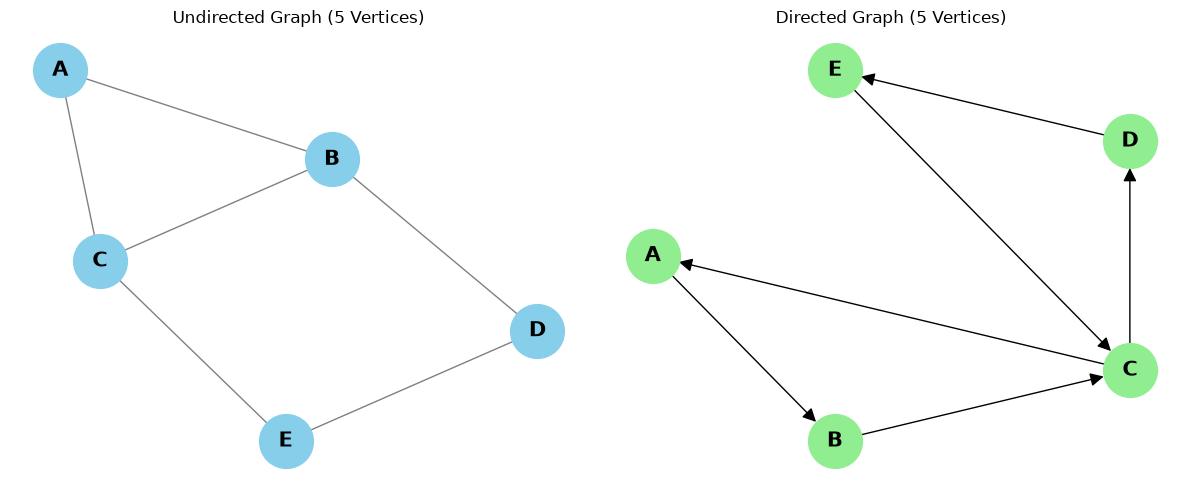

In [3]:
plt.figure(figsize=(12, 5))

# Visualisasi Undirected Graph
plt.subplot(1, 2, 1)
pos_undirected = nx.spring_layout(G_undirected)
nx.draw(G_undirected, pos_undirected, with_labels=True, node_color='skyblue', node_size=1500, edge_color='gray', font_size=15, font_weight='bold')
plt.title("Undirected Graph (5 Vertices)")

# Visualisasi Directed Graph
plt.subplot(1, 2, 2)
pos_directed = nx.shell_layout(G_directed)
nx.draw(G_directed, pos_directed, with_labels=True, node_color='lightgreen', node_size=1500, edge_color='black', font_size=15, font_weight='bold', arrows=True, arrowsize=20)
plt.title("Directed Graph (5 Vertices)")

plt.tight_layout()
plt.show()

## 3. Analisis Undirected Graph

In [4]:
print("=== ANALISIS UNDIRECTED GRAPH ===")

# 1. Adjacency Matrix
adj_matrix_undirected = nx.to_numpy_array(G_undirected)
df_adj_undirected = pd.DataFrame(adj_matrix_undirected, index=vertices, columns=vertices)
print("\n1. Adjacency Matrix:")
display(df_adj_undirected)

# 2. Degree masing-masing vertex
degrees_undirected = dict(G_undirected.degree())
print(f"\n2. Degree masing-masing vertex: {degrees_undirected}")

# 3. Rata-rata Degree
avg_degree_undirected = sum(degrees_undirected.values()) / len(G_undirected)
print(f"3. Rata-rata Degree: {avg_degree_undirected:.2f}")

# 4. Density
density_undirected = nx.density(G_undirected)
print(f"4. Graph Density: {density_undirected:.2f}")

# 5. Distribusi Derajat (Degree Distribution)
degree_freq = nx.degree_histogram(G_undirected)
print(f"5. Degree Distribution (frekuensi): {degree_freq}")

=== ANALISIS UNDIRECTED GRAPH ===

1. Adjacency Matrix:


,A,B,C,D,E
A,0.0,1.0,1.0,0.0,0.0
B,1.0,0.0,1.0,1.0,0.0
C,1.0,1.0,0.0,0.0,1.0
D,0.0,1.0,0.0,0.0,1.0
E,0.0,0.0,1.0,1.0,0.0



2. Degree masing-masing vertex: {'A': 2, 'B': 3, 'C': 3, 'D': 2, 'E': 2}
3. Rata-rata Degree: 2.40
4. Graph Density: 0.60
5. Degree Distribution (frekuensi): [0, 0, 3, 2]


In [5]:
# 6. Rata-rata Panjang Lintasan Terpendek (Average Shortest Path Length)
avg_path_undirected = nx.average_shortest_path_length(G_undirected)
print(f"6. Rata-rata Panjang Lintasan Terpendek: {avg_path_undirected:.2f}")

# 7. Koefisien Klasterisasi (Clustering Coefficient) masing-masing vertex
clustering_undirected = nx.clustering(G_undirected)
print(f"7. Clustering Coefficient masing-masing vertex: {clustering_undirected}")
avg_clustering_undirected = nx.average_clustering(G_undirected)
print(f"   Rata-rata Clustering Coefficient: {avg_clustering_undirected:.2f}")

6. Rata-rata Panjang Lintasan Terpendek: 1.40
7. Clustering Coefficient masing-masing vertex: {'A': 1.0, 'B': 0.3333333333333333, 'C': 0.3333333333333333, 'D': 0, 'E': 0}
   Rata-rata Clustering Coefficient: 0.33


## 4. Analisis Directed Graph

In [6]:
print("=== ANALISIS DIRECTED GRAPH ===")

# 1. Adjacency Matrix
adj_matrix_directed = nx.to_numpy_array(G_directed)
df_adj_directed = pd.DataFrame(adj_matrix_directed, index=vertices, columns=vertices)
print("\n1. Adjacency Matrix:")
display(df_adj_directed)

# 2. Degree (In-degree, Out-degree, Total Degree)
in_degree = dict(G_directed.in_degree())
out_degree = dict(G_directed.out_degree())
total_degree = {n: in_degree[n] + out_degree[n] for n in G_directed.nodes()}

df_degrees = pd.DataFrame({
    'In-Degree': in_degree,
    'Out-Degree': out_degree,
    'Total Degree': total_degree
})
print("\n2. Detail Degree:")
display(df_degrees)

# 3. Rata-rata Degree
avg_in = sum(in_degree.values()) / len(G_directed)
avg_out = sum(out_degree.values()) / len(G_directed)
avg_total = sum(total_degree.values()) / len(G_directed)
print(f"\n3. Rata-rata Degree:")
print(f"   - In-Degree: {avg_in:.2f}")
print(f"   - Out-Degree: {avg_out:.2f}")
print(f"   - Total Degree: {avg_total:.2f}")

# 4. Density
density_directed = nx.density(G_directed)
print(f"\n4. Graph Density: {density_directed:.2f}")

=== ANALISIS DIRECTED GRAPH ===

1. Adjacency Matrix:


,A,B,C,D,E
A,0.0,1.0,0.0,0.0,0.0
B,0.0,0.0,1.0,0.0,0.0
C,1.0,0.0,0.0,1.0,0.0
D,0.0,0.0,0.0,0.0,1.0
E,0.0,0.0,1.0,0.0,0.0



2. Detail Degree:


,In-Degree,Out-Degree,Total Degree
A,1,1,2
B,1,1,2
C,2,2,4
D,1,1,2
E,1,1,2



3. Rata-rata Degree:
   - In-Degree: 1.20
   - Out-Degree: 1.20
   - Total Degree: 2.40

4. Graph Density: 0.30


In [7]:
# 5. Distribusi Derajat (untuk Total Degree)
degree_values = list(total_degree.values())
unique_degrees = sorted(set(degree_values))
degree_dist = {d: degree_values.count(d) for d in unique_degrees}
print(f"5. Distribusi Derajat (Total Degree) [Derajat: Frekuensi]: {degree_dist}")

# 6. Rata-rata Panjang Lintasan Terpendek (Average Shortest Path Length)
try:
    avg_path_directed = nx.average_shortest_path_length(G_directed)
    print(f"6. Rata-rata Panjang Lintasan Terpendek: {avg_path_directed:.2f}")
except nx.NetworkXError as e:
    print(f"6. Rata-rata Panjang Lintasan Terpendek: Error ({e})")

# 7. Koefisien Klasterisasi (Clustering Coefficient) masing-masing vertex
clustering_directed = nx.clustering(G_directed)
print(f"7. Clustering Coefficient masing-masing vertex: {clustering_directed}")
avg_clustering_directed = nx.average_clustering(G_directed)
print(f"   Rata-rata Clustering Coefficient: {avg_clustering_directed:.2f}")

5. Distribusi Derajat (Total Degree) [Derajat: Frekuensi]: {2: 4, 4: 1}
6. Rata-rata Panjang Lintasan Terpendek: 2.10
7. Clustering Coefficient masing-masing vertex: {'A': 0.5, 'B': 0.5, 'C': 0.16666666666666666, 'D': 0.5, 'E': 0.5}
   Rata-rata Clustering Coefficient: 0.43


## 5. Ringkasan Hasil
Berikut adalah ringkasan perbandingan antara Undirected dan Directed Graph yang telah kita buat.

In [8]:
summary_data = {
    'Metrik': ['Jumlah Vertex', 'Jumlah Edge', 'Rata-rata Degree', 'Density', 'Avg Shortest Path', 'Avg Clustering'],
    'Undirected': [
        G_undirected.number_of_nodes(),
        G_undirected.number_of_edges(),
        avg_degree_undirected,
        density_undirected,
        avg_path_undirected,
        avg_clustering_undirected
    ],
    'Directed': [
        G_directed.number_of_nodes(),
        G_directed.number_of_edges(),
        avg_total, # Menggunakan total degree untuk perbandingan
        density_directed,
        avg_path_directed if 'avg_path_directed' in locals() else "N/A",
        avg_clustering_directed
    ]
}
df_summary = pd.DataFrame(summary_data)
display(df_summary)

,Metrik,Undirected,Directed
0,Jumlah Vertex,5.000000,5.000000
1,Jumlah Edge,6.000000,6.000000
2,Rata-rata Degree,2.400000,2.400000
3,Density,0.600000,0.300000
4,Avg Shortest Path,1.400000,2.100000
5,Avg Clustering,0.333333,0.433333
